# Transformer básico para series de tiempo
Objetivo: predecir el siguiente valor con embeddings, codificación posicional y self-attention multi-cabeza.


## Concepto
Cada posición crea consultas, claves y valores. La atención relaciona las posiciones de la ventana y la codificación posicional conserva el orden temporal.


In [1]:
# Instala las dependencias necesarias cuando se ejecuta en Google Colab.
!pip -q install tensorflow scikit-learn pandas matplotlib



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Importa NumPy para cálculos numéricos y arreglos.
import numpy as np
# Importa Pandas para organizar los datos en tablas.
import pandas as pd
# Importa Matplotlib para crear gráficas.
import matplotlib.pyplot as plt
# Importa TensorFlow y Keras para construir redes neuronales.
import tensorflow as tf
# Importa el escalador que normaliza los datos.
from sklearn.preprocessing import MinMaxScaler
# Importa métricas para evaluar las predicciones.
from sklearn.metrics import mean_absolute_error, mean_squared_error
# Fija la semilla de NumPy para que el experimento sea reproducible.
np.random.seed(42); tf.keras.utils.set_random_seed(42)
# Define una función que genera la serie temporal de ejemplo.
def serie(n=1600):
    # Crea el índice temporal de la serie.
    t=np.arange(n)
    # Devuelve la serie con tendencia, estacionalidad y ruido.
    return pd.DataFrame({"tiempo":t,"valor":.0008*t+.55*np.sin(2*np.pi*t/50)+.2*np.sin(2*np.pi*t/12)+np.random.normal(0,.07,n)})
# Define una función que convierte la serie en ventanas de entrada y objetivos.
def ventanas(a,p=48):
    # Devuelve las ventanas X y los valores objetivo y como arreglos NumPy.
    return np.array([a[i-p:i] for i in range(p,len(a))])[...,None],np.array([a[i] for i in range(p,len(a))])


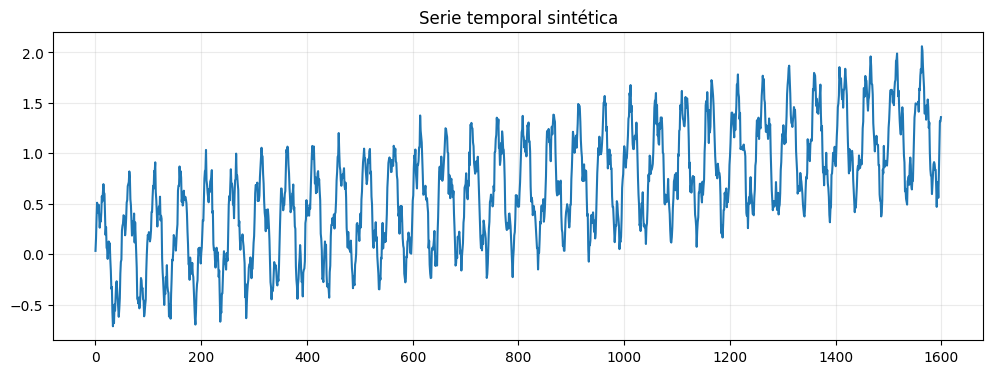

(1232, 48, 1) (320, 48, 1)


In [3]:
# Establece la longitud de cada ventana temporal.
PASOS=48
# Genera los datos que se utilizarán en el experimento.
datos=serie()
# Crea una figura para la visualización.
plt.figure(figsize=(12,4)); plt.plot(datos.tiempo,datos.valor); plt.title("Serie temporal sintética"); plt.grid(alpha=.25); plt.show()
# Calcula el punto de corte temporal entre entrenamiento y prueba.
limite=int(len(datos)*.8)
# Ajusta el escalador solo con entrenamiento para evitar fuga de información.
escalador=MinMaxScaler().fit(datos[["valor"]].iloc[:limite])
# Normaliza toda la serie usando los parámetros aprendidos en entrenamiento.
valores=escalador.transform(datos[["valor"]]).ravel()
# Construye las ventanas de entrada X y los objetivos y.
X,y=ventanas(valores,PASOS)
# Ajusta el corte porque las primeras observaciones forman la primera ventana.
corte=limite-PASOS
# Separa las ventanas y objetivos en conjuntos de entrenamiento y prueba.
X_train,X_test,y_train,y_test=X[:corte],X[corte:],y[:corte],y[corte:]
# Imprime una métrica, forma de arreglo o comprobación relevante.
print(X_train.shape,X_test.shape)


In [4]:
# Define una capa de codificación posicional senoidal.
class Posicion(tf.keras.layers.Layer):
    # Inicializa las capas entrenables de la capa personalizada.
    def __init__(self,p,d,**kw):
        # Inicializa la clase base de Keras.
        super().__init__(**kw)
        # Calcula ángulos para codificar cada posición y dimensión.
        i=np.arange(p)[:,None]; j=np.arange(d)[None,:]; a=i/np.power(10000,(2*(j//2))/d)
        # Inicializa la matriz de codificación posicional.
        z=np.zeros((p,d)); z[:,0::2]=np.sin(a[:,0::2]); z[:,1::2]=np.cos(a[:,1::2]); self.z=tf.constant(z[None],tf.float32)
    # Define el cálculo que ejecuta la capa durante el paso hacia adelante.
    def call(self,x): return x+self.z
# Define un bloque encoder del Transformer.
def bloque(x,d=32):
    # Aplica self-attention multi-cabeza a la secuencia.
    a=tf.keras.layers.MultiHeadAttention(num_heads=4,key_dim=8)(x,x)
    # Normaliza la salida residual del bloque Transformer.
    x=tf.keras.layers.LayerNormalization(epsilon=1e-6)(x+a)
    # Crea la red feed-forward que transforma cada posición.
    f=tf.keras.Sequential([tf.keras.layers.Dense(64,activation="relu"),tf.keras.layers.Dense(d)])(x)
    # Ejecuta esta instrucción como parte del flujo de preparación, modelado o evaluación.
    return tf.keras.layers.LayerNormalization(epsilon=1e-6)(x+f)
# Declara la entrada con una ventana y una variable por instante.
entrada=tf.keras.Input(shape=(PASOS,1))
# Ejecuta esta instrucción como parte del flujo de preparación, modelado o evaluación.
x=Posicion(PASOS,32)(tf.keras.layers.Dense(32,name="embedding")(entrada))
# Apila bloques encoder para aprender representaciones más complejas.
x=bloque(x); x=bloque(x); x=tf.keras.layers.GlobalAveragePooling1D()(x)
# Construye el modelo que conecta la entrada con la predicción.
modelo=tf.keras.Model(entrada,tf.keras.layers.Dense(1)(x))
# Configura el optimizador, la función de pérdida y la métrica de entrenamiento.
modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="mse",metrics=["mae"])
# Muestra la arquitectura y el número de parámetros del modelo.
modelo.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding (Dense)   │ (None, 48, 32)    │         64 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ posicion (Posicion) │ (None, 48, 32)    │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 48, 32)    │      4,224 │ posicion[0][0],   │
│ (MultiHeadAttentio… │                   │            │ posicion[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 48, 32)    │          0 │ posicion[0][0],   │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 48, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 48, 32)    │      4,192 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 48, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 48, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 48, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 48, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 48, 32)    │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 48, 32)    │      4,192 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 48, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 48, 32)    │         64 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         33 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,185 (67.13 KB)

 Trainable params: 17,185 (67.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - loss: 0.3234 - mae: 0.4145 - val_loss: 0.1555 - val_mae: 0.3591
Epoch 2/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0407 - mae: 0.1632 - val_loss: 0.0531 - val_mae: 0.1888
Epoch 3/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0313 - mae: 0.1461 - val_loss: 0.0528 - val_mae: 0.1897
Epoch 4/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0267 - mae: 0.1351 - val_loss: 0.0401 - val_mae: 0.1641
Epoch 5/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0197 - mae: 0.1149 - val_loss: 0.0218 - val_mae: 0.1211
Epoch 6/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0096 - mae: 0.0788 - val_loss: 0.0152 - val_mae: 0.1054
Epoch 7/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0045 - mae: 0.0557 - val_loss: 0.0067 - val_mae: 0.0675
Epoch 8/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0035 - mae: 0.0492 - val_loss: 0.0051 - val_mae: 0.0591
Epoch 9/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - loss: 0.00

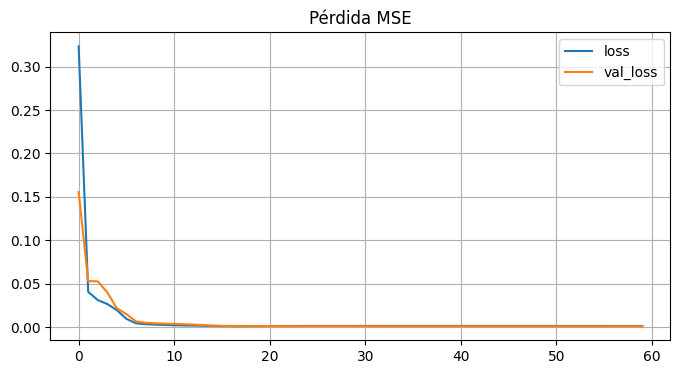

MAE: 0.0668818838995606 RMSE: 0.08302683353965037


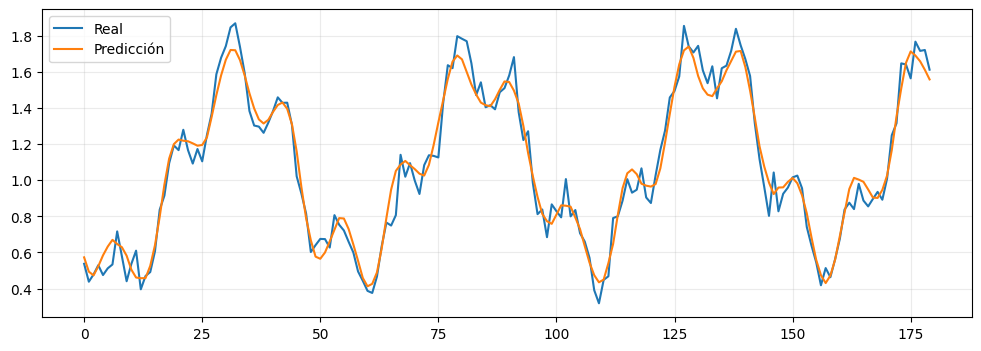

In [5]:
# Entrena el modelo y guarda las métricas de cada época.
historial=modelo.fit(X_train,y_train,validation_split=.15,epochs=60,batch_size=32,callbacks=[tf.keras.callbacks.EarlyStopping(patience=8,restore_best_weights=True)],verbose=1)
# Convierte el historial a tabla y grafica las pérdidas.
pd.DataFrame(historial.history)[["loss","val_loss"]].plot(figsize=(8,4),grid=True,title="Pérdida MSE"); plt.show()
# Genera predicciones normalizadas para el conjunto de prueba.
p=modelo.predict(X_test,verbose=0).ravel()
# Devuelve los valores reales a la escala original.
real=escalador.inverse_transform(y_test.reshape(-1,1)).ravel()
# Devuelve las predicciones a la escala original.
pred=escalador.inverse_transform(p.reshape(-1,1)).ravel()
# Calcula RMSE como la raíz cuadrada del error cuadrático medio.
rmse=np.sqrt(mean_squared_error(real,pred))
# Imprime una métrica, forma de arreglo o comprobación relevante.
print("MAE:",mean_absolute_error(real,pred),"RMSE:",rmse)
# Crea una figura para la visualización.
plt.figure(figsize=(12,4)); plt.plot(real[:180],label="Real"); plt.plot(pred[:180],label="Predicción"); plt.legend(); plt.grid(alpha=.25); plt.show()


## Análisis
Compare las métricas, la estabilidad de la pérdida de validación y el costo de entrenamiento con el notebook de atención. El Transformer procesa dependencias largas en paralelo, aunque con pocos datos puede requerir regularización.
